# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Employee Label Dataset](https://www.kaggle.com/datasets/tawfikelmetwally/employee-dataset)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('Employee.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0
1,Bachelors,2013,Pune,1,28,Female,No,3,1
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0
3,Masters,2016,Bangalore,3,27,Male,No,5,1
4,Masters,2017,Pune,3,24,Male,Yes,2,1


## last Five row

In [4]:
df.tail()

,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
4648,Bachelors,2013,Bangalore,3,26,Female,No,4,0
4649,Masters,2013,Pune,2,37,Male,No,2,1
4650,Masters,2018,New Delhi,3,27,Male,No,5,1
4651,Bachelors,2012,Bangalore,3,30,Male,Yes,2,0
4652,Bachelors,2015,Bangalore,3,33,Male,Yes,4,0


## Shape of our dataset

In [5]:
df.shape

(4653, 9)

## List out all columns

In [6]:
df.columns

Index(['Education', 'JoiningYear', 'City', 'PaymentTier', 'Age', 'Gender',
       'EverBenched', 'ExperienceInCurrentDomain', 'LeaveOrNot'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

Education                    object
JoiningYear                   int64
City                         object
PaymentTier                   int64
Age                           int64
Gender                       object
EverBenched                  object
ExperienceInCurrentDomain     int64
LeaveOrNot                    int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4653 entries, 0 to 4652
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Education                  4653 non-null   object
 1   JoiningYear                4653 non-null   int64 
 2   City                       4653 non-null   object
 3   PaymentTier                4653 non-null   int64 
 4   Age                        4653 non-null   int64 
 5   Gender                     4653 non-null   object
 6   EverBenched                4653 non-null   object
 7   ExperienceInCurrentDomain  4653 non-null   int64 
 8   LeaveOrNot                 4653 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 327.3+ KB


## Check Null Value

In [9]:
df.isnull().sum()

Education                    0
JoiningYear                  0
City                         0
PaymentTier                  0
Age                          0
Gender                       0
EverBenched                  0
ExperienceInCurrentDomain    0
LeaveOrNot                   0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(1889)

## Drop Duplicate Value

In [11]:
df.drop_duplicates(inplace=True)

## Summary

In [12]:
df.describe()

,JoiningYear,PaymentTier,Age,ExperienceInCurrentDomain,LeaveOrNot
count,2764.000000,2764.000000,2764.000000,2764.000000,2764.000000
mean,2015.090449,2.636035,30.952967,2.644356,0.393632
std,1.885943,0.624001,5.108872,1.610610,0.488643
min,2012.000000,1.000000,22.000000,0.000000,0.000000
25%,2013.000000,2.000000,27.000000,1.000000,0.000000
50%,2015.000000,3.000000,30.000000,2.000000,0.000000
75%,2017.000000,3.000000,35.000000,4.000000,1.000000
max,2018.000000,3.000000,41.000000,7.000000,1.000000


# EDA

In [13]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

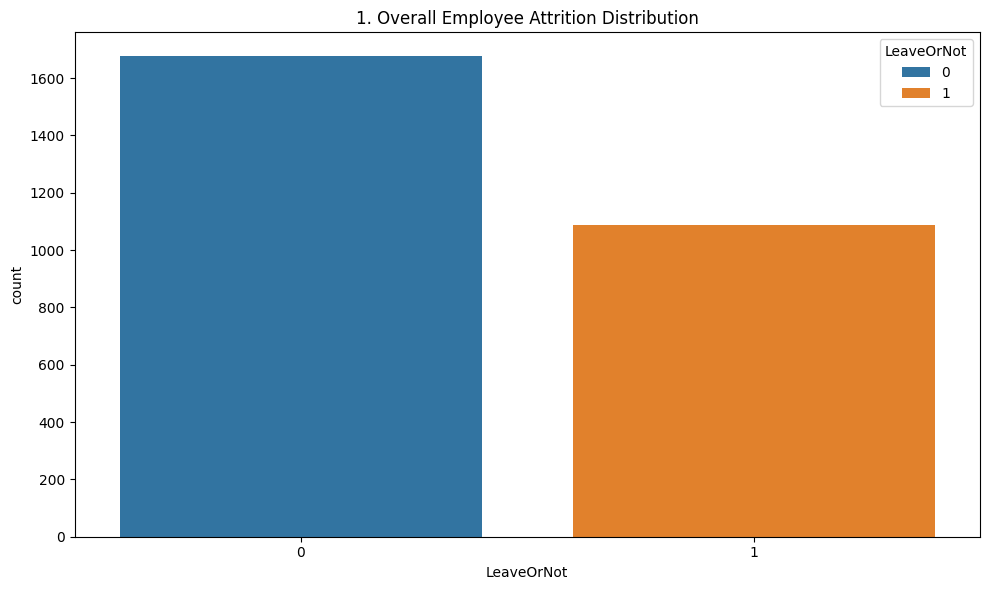

In [14]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='LeaveOrNot', hue='LeaveOrNot')
plt.title(f'{plot_no}. Overall Employee Attrition Distribution')
show_fig()
plot_no += 1

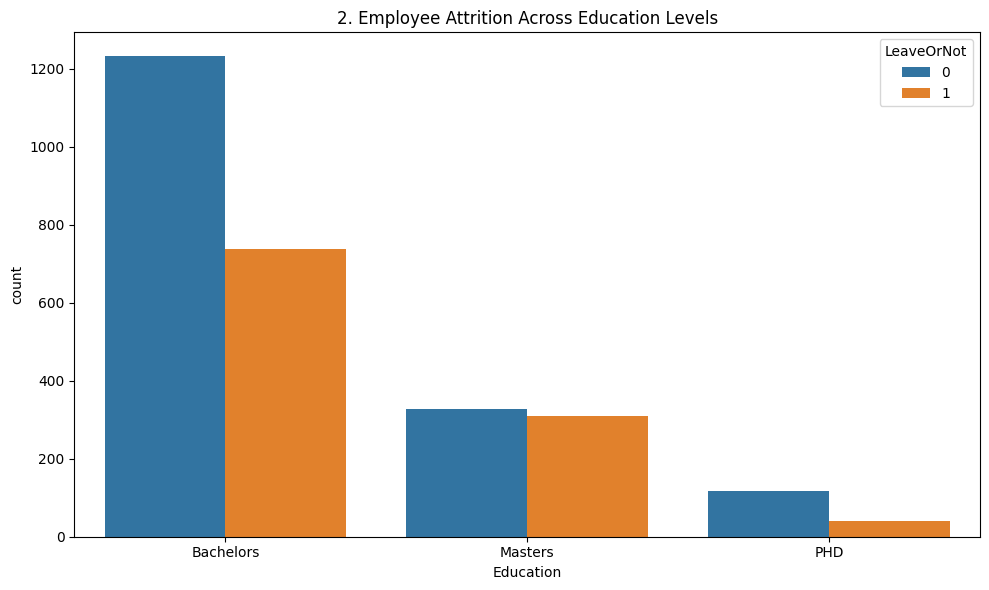

In [15]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Education', hue='LeaveOrNot')
plt.title(f'{plot_no}. Employee Attrition Across Education Levels')
show_fig()
plot_no += 1

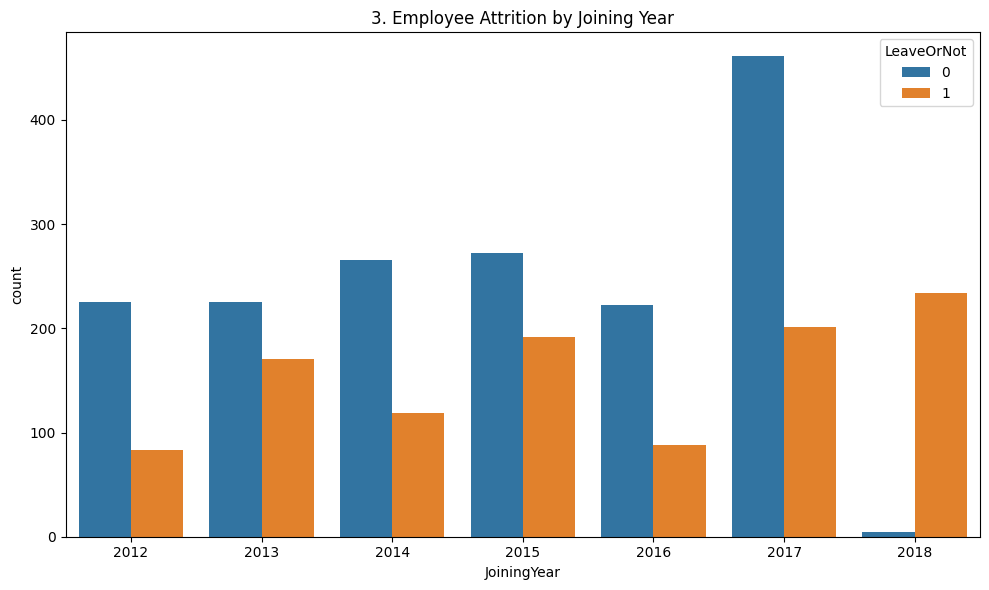

In [16]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='JoiningYear', hue='LeaveOrNot')
plt.title(f'{plot_no}. Employee Attrition by Joining Year')
show_fig()
plot_no += 1

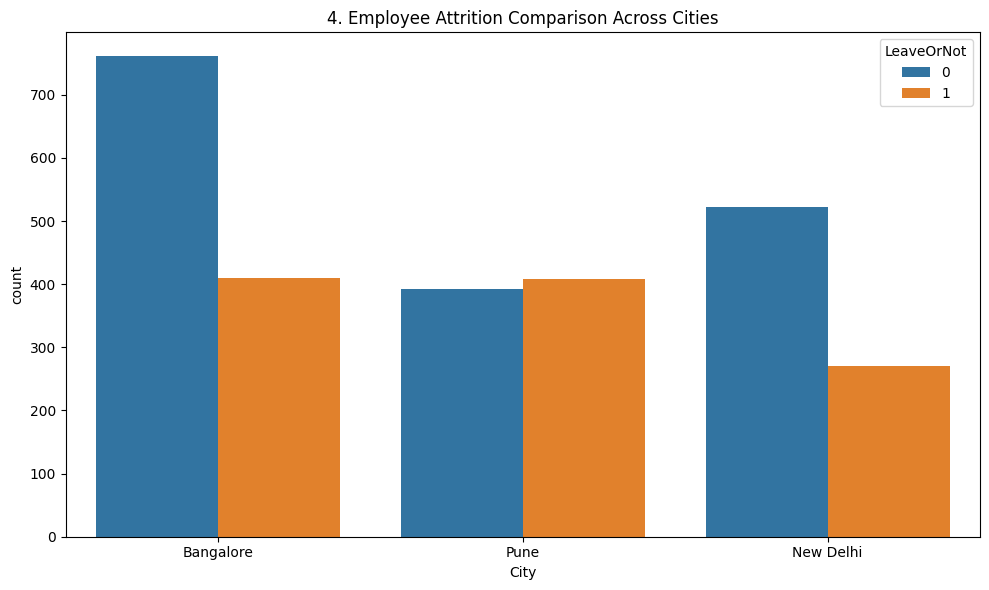

In [17]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='City', hue='LeaveOrNot')
plt.title(f'{plot_no}. Employee Attrition Comparison Across Cities')
show_fig()
plot_no += 1

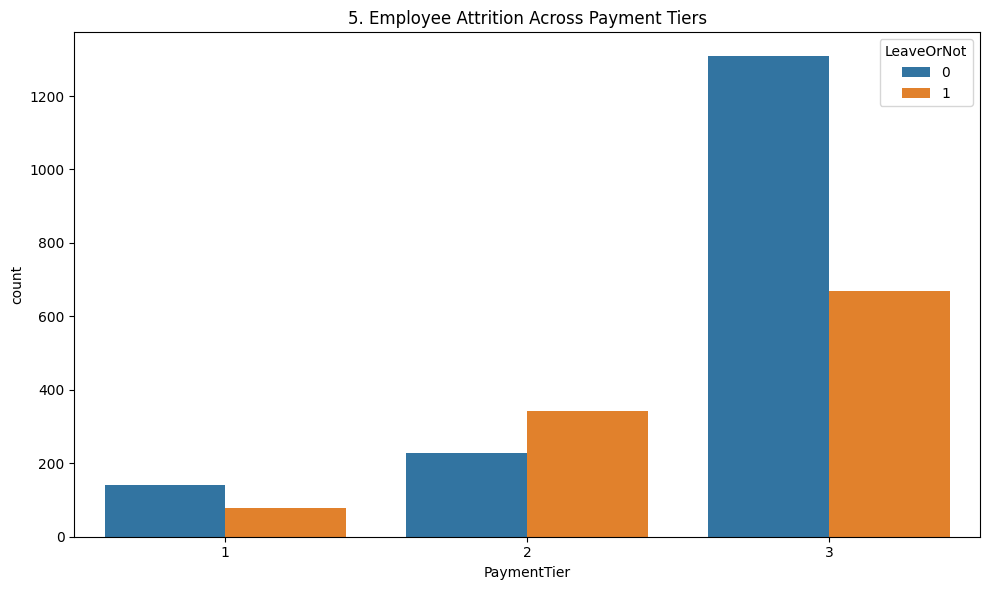

In [18]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='PaymentTier', hue='LeaveOrNot')
plt.title(f'{plot_no}. Employee Attrition Across Payment Tiers')
show_fig()
plot_no += 1

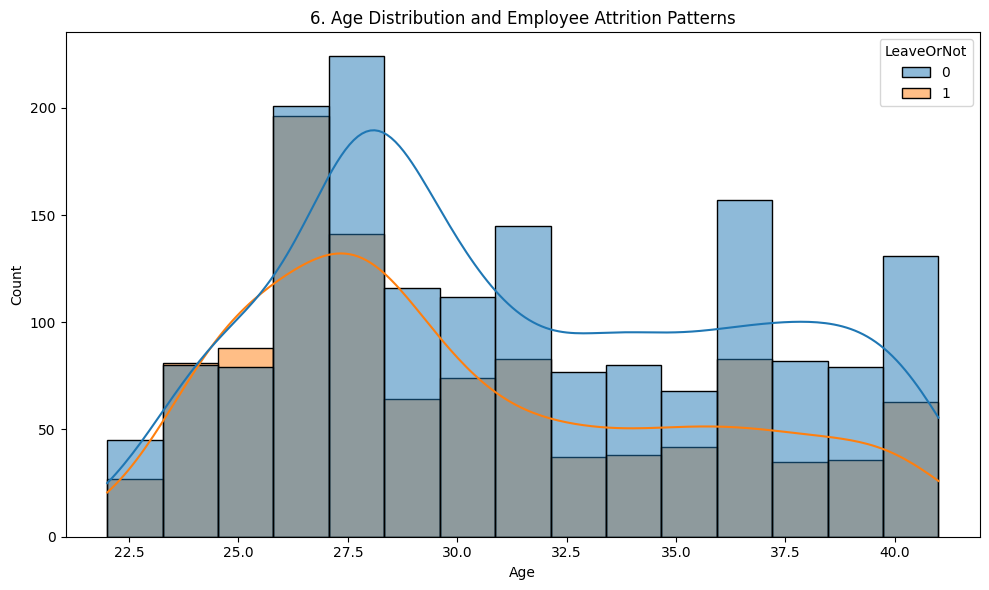

In [19]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Age', hue='LeaveOrNot', bins=15, kde=True, multiple='layer')
plt.title(f'{plot_no}. Age Distribution and Employee Attrition Patterns')
show_fig()
plot_no += 1

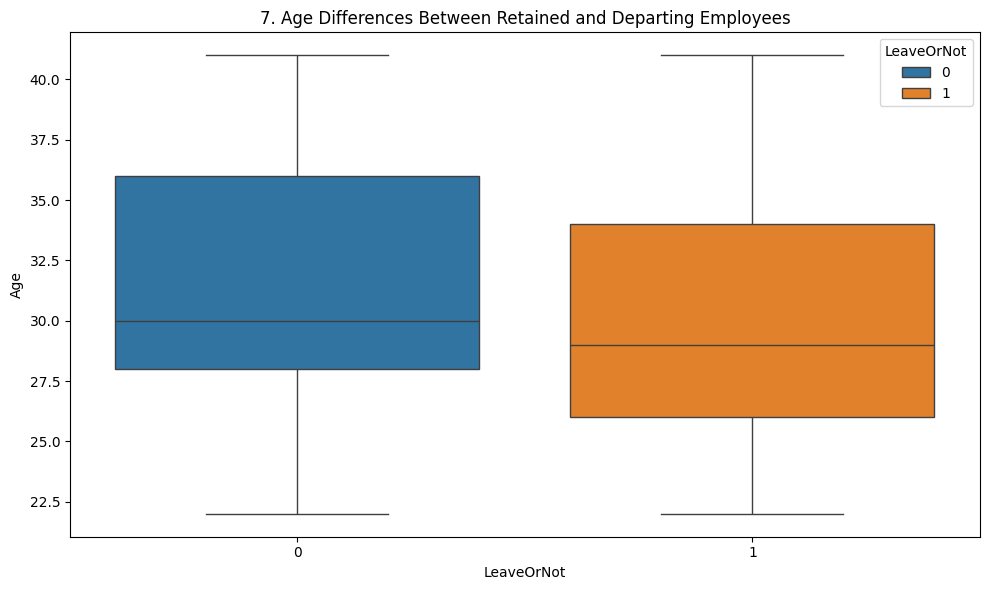

In [20]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='LeaveOrNot', y='Age', hue='LeaveOrNot')
plt.title(f'{plot_no}. Age Differences Between Retained and Departing Employees')
show_fig()
plot_no += 1

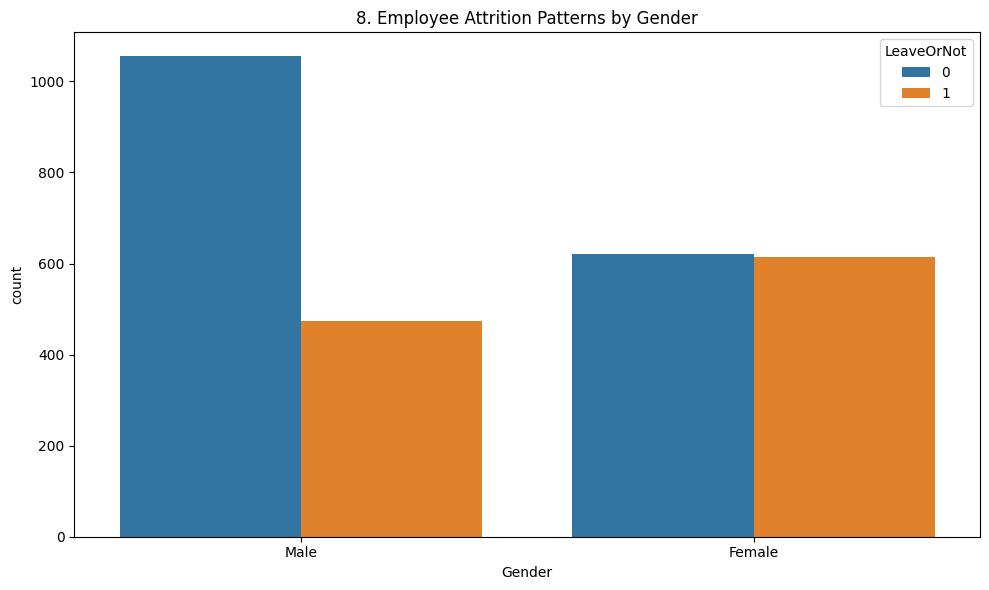

In [21]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Gender', hue='LeaveOrNot')
plt.title(f'{plot_no}. Employee Attrition Patterns by Gender')
show_fig()
plot_no += 1

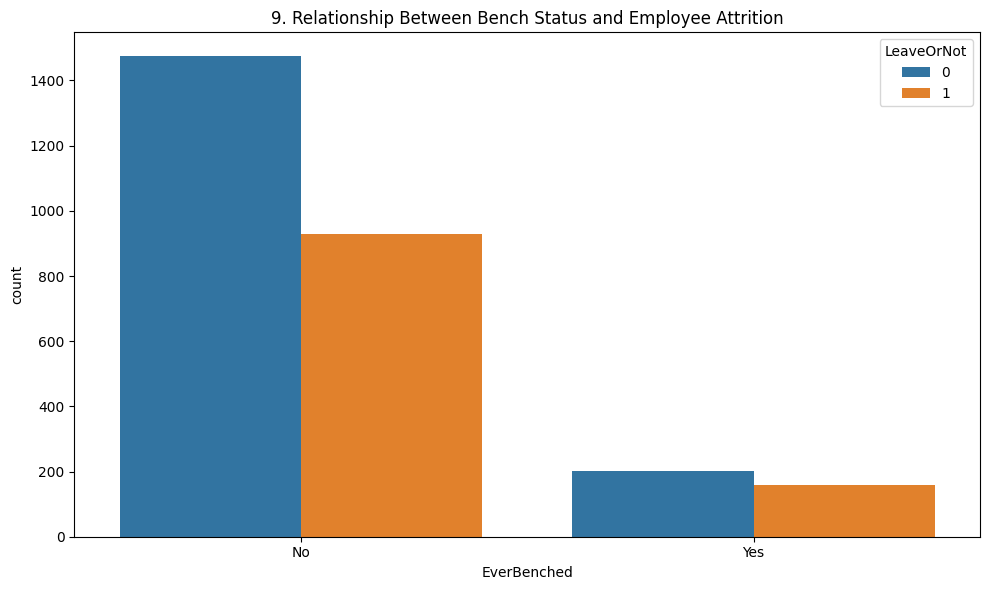

In [22]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='EverBenched', hue='LeaveOrNot')
plt.title(f'{plot_no}. Relationship Between Bench Status and Employee Attrition')
show_fig()
plot_no += 1

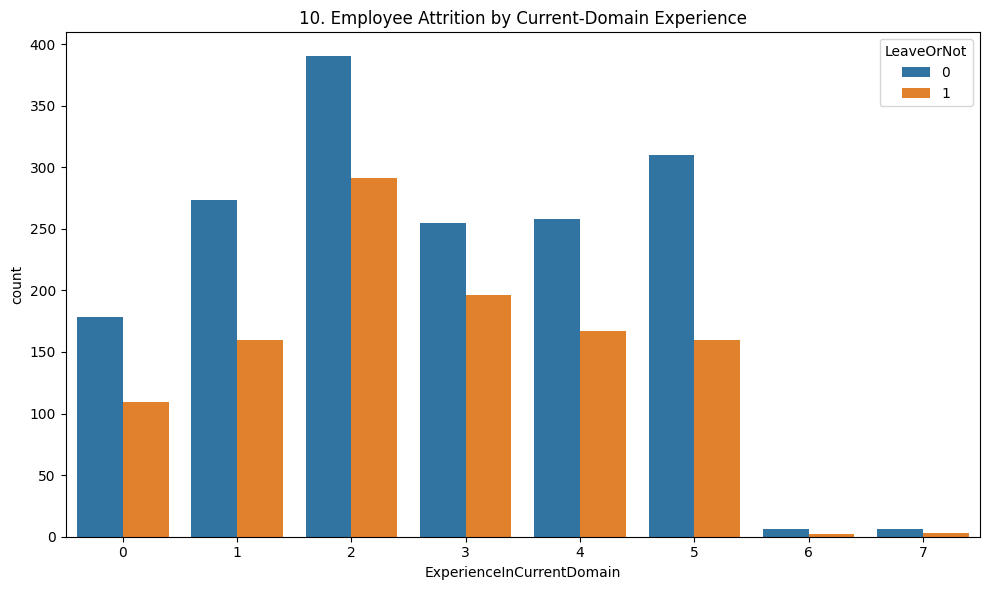

In [23]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='ExperienceInCurrentDomain', hue='LeaveOrNot')
plt.title(f'{plot_no}. Employee Attrition by Current-Domain Experience')
show_fig()
plot_no += 1

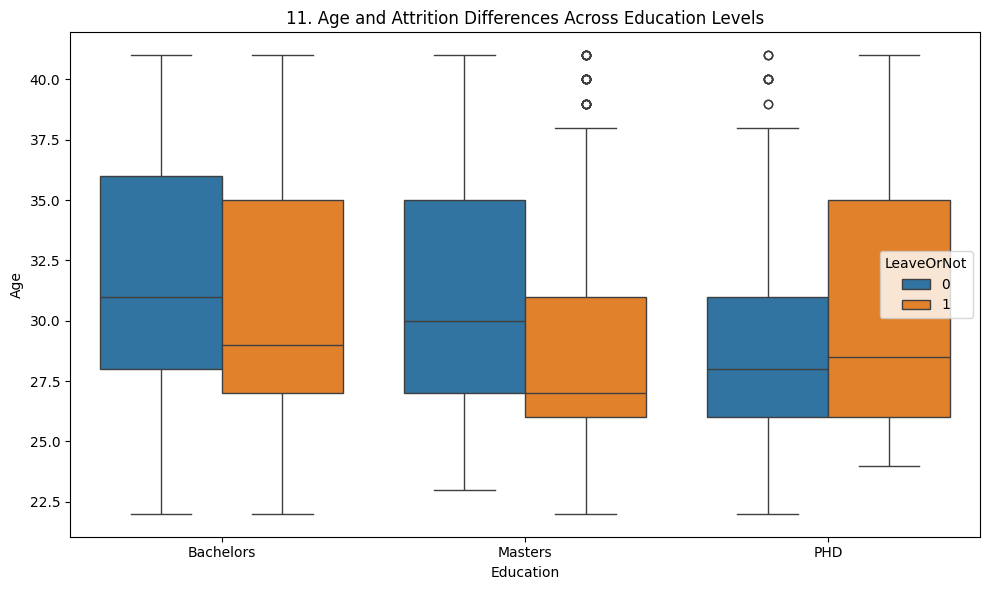

In [24]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Education', y='Age', hue='LeaveOrNot')
plt.title(f'{plot_no}. Age and Attrition Differences Across Education Levels')
show_fig()
plot_no += 1

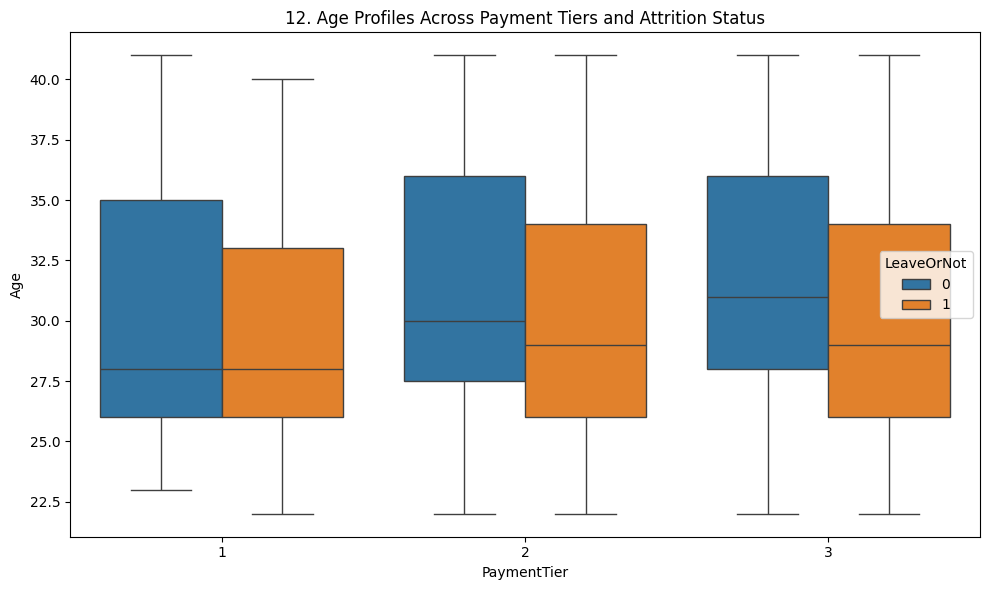

In [25]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='PaymentTier', y='Age', hue='LeaveOrNot')
plt.title(f'{plot_no}. Age Profiles Across Payment Tiers and Attrition Status')
show_fig()
plot_no += 1

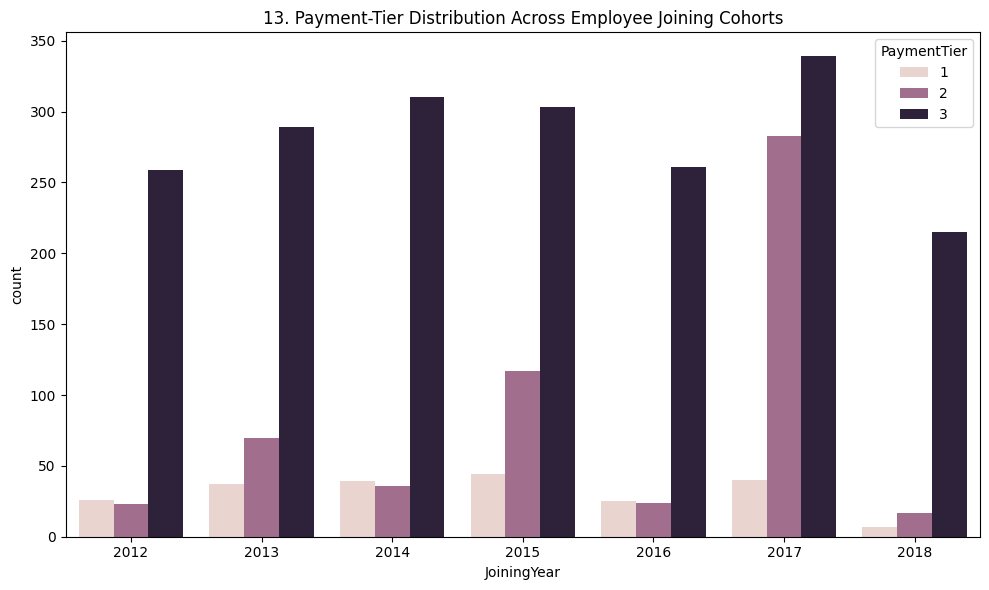

In [26]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='JoiningYear', hue='PaymentTier')
plt.title(f'{plot_no}. Payment-Tier Distribution Across Employee Joining Cohorts')
show_fig()
plot_no += 1

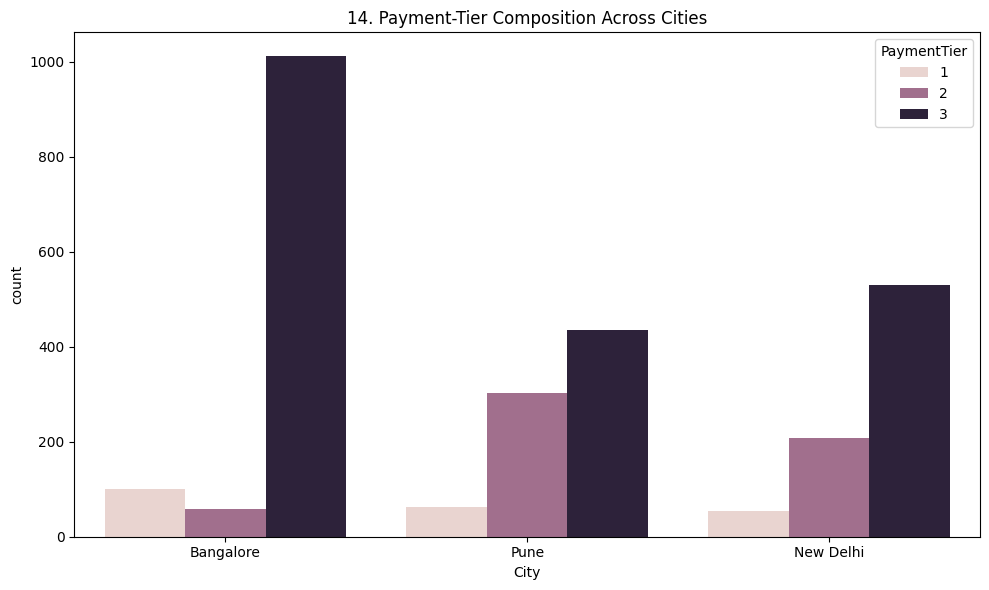

In [27]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='City', hue='PaymentTier')
plt.title(f'{plot_no}. Payment-Tier Composition Across Cities')
show_fig()
plot_no += 1

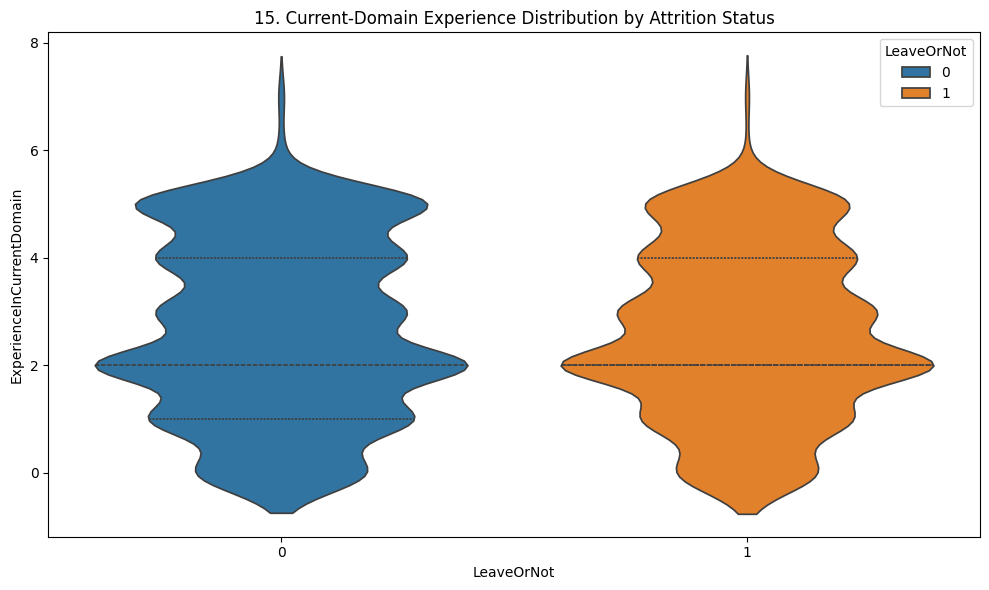

In [28]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='LeaveOrNot', y='ExperienceInCurrentDomain', hue='LeaveOrNot', inner='quartile')
plt.title(f'{plot_no}. Current-Domain Experience Distribution by Attrition Status')
show_fig()
plot_no += 1

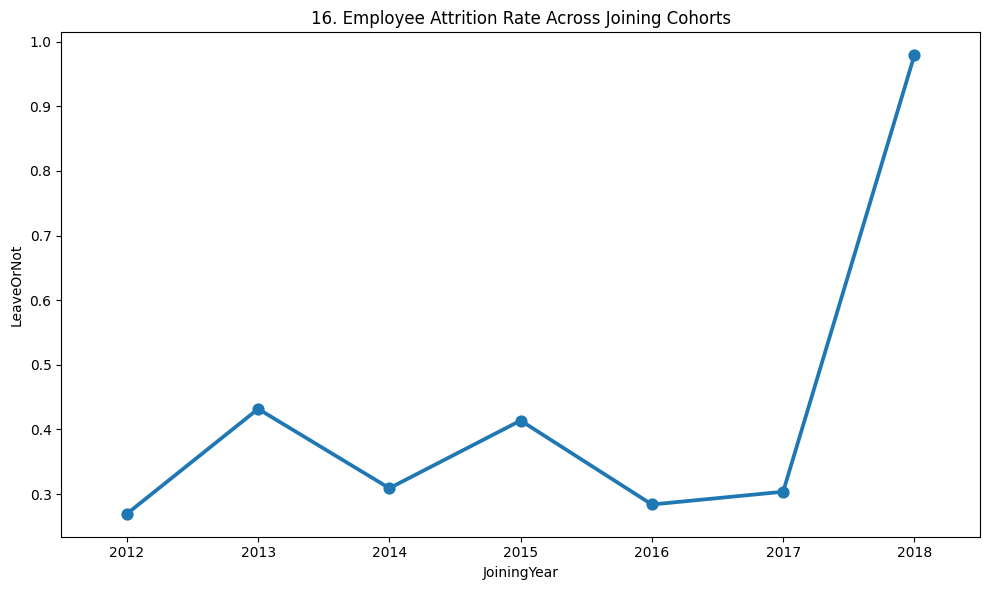

In [29]:
fig = plt.figure(figsize=(10,6))
sns.pointplot(data=df, x='JoiningYear', y='LeaveOrNot', errorbar=None)
plt.title(f'{plot_no}. Employee Attrition Rate Across Joining Cohorts')
show_fig()
plot_no += 1

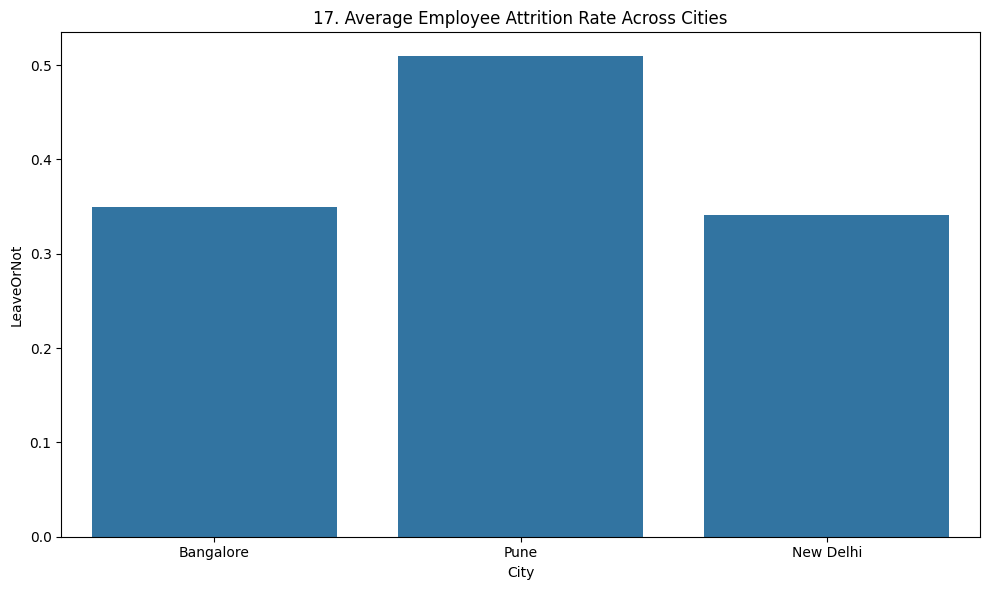

In [30]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='City', y='LeaveOrNot', errorbar=None)
plt.title(f'{plot_no}. Average Employee Attrition Rate Across Cities')
show_fig()
plot_no += 1

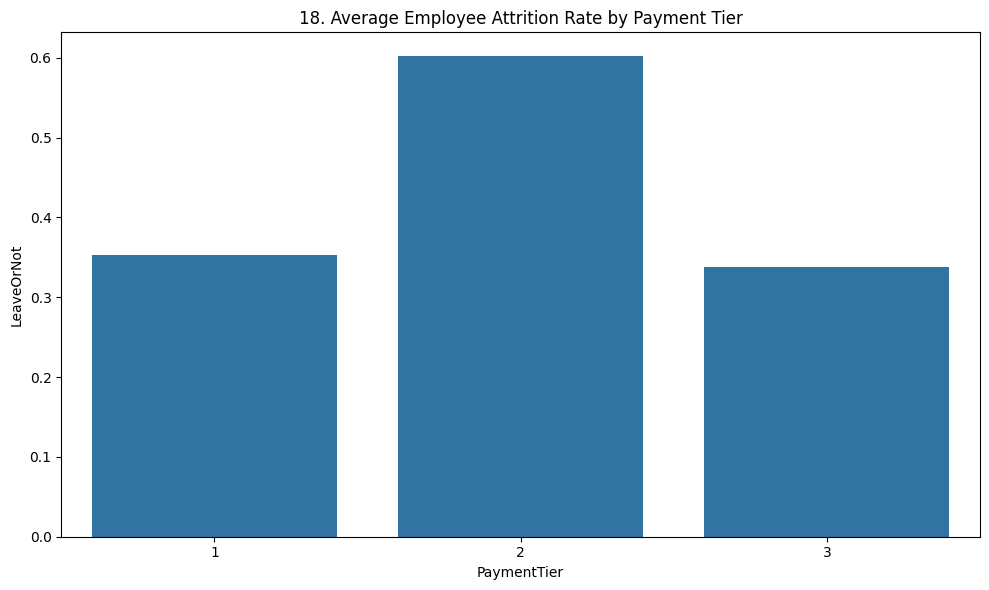

In [31]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='PaymentTier', y='LeaveOrNot', errorbar=None)
plt.title(f'{plot_no}. Average Employee Attrition Rate by Payment Tier')
show_fig()
plot_no += 1

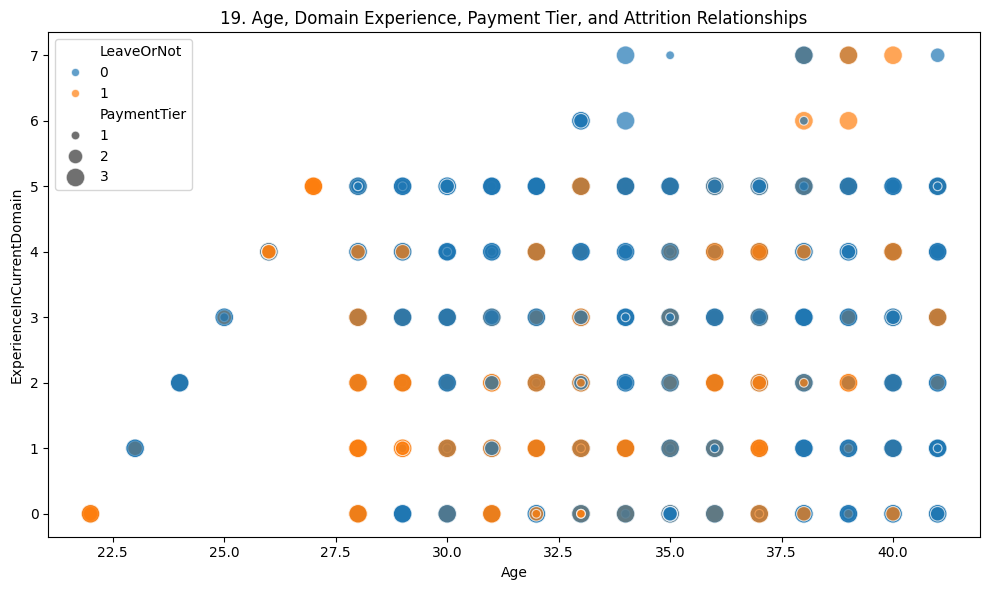

In [32]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Age', y='ExperienceInCurrentDomain', hue='LeaveOrNot', size='PaymentTier', sizes=(40,180), alpha=0.7)
plt.title(f'{plot_no}. Age, Domain Experience, Payment Tier, and Attrition Relationships')
show_fig()
plot_no += 1

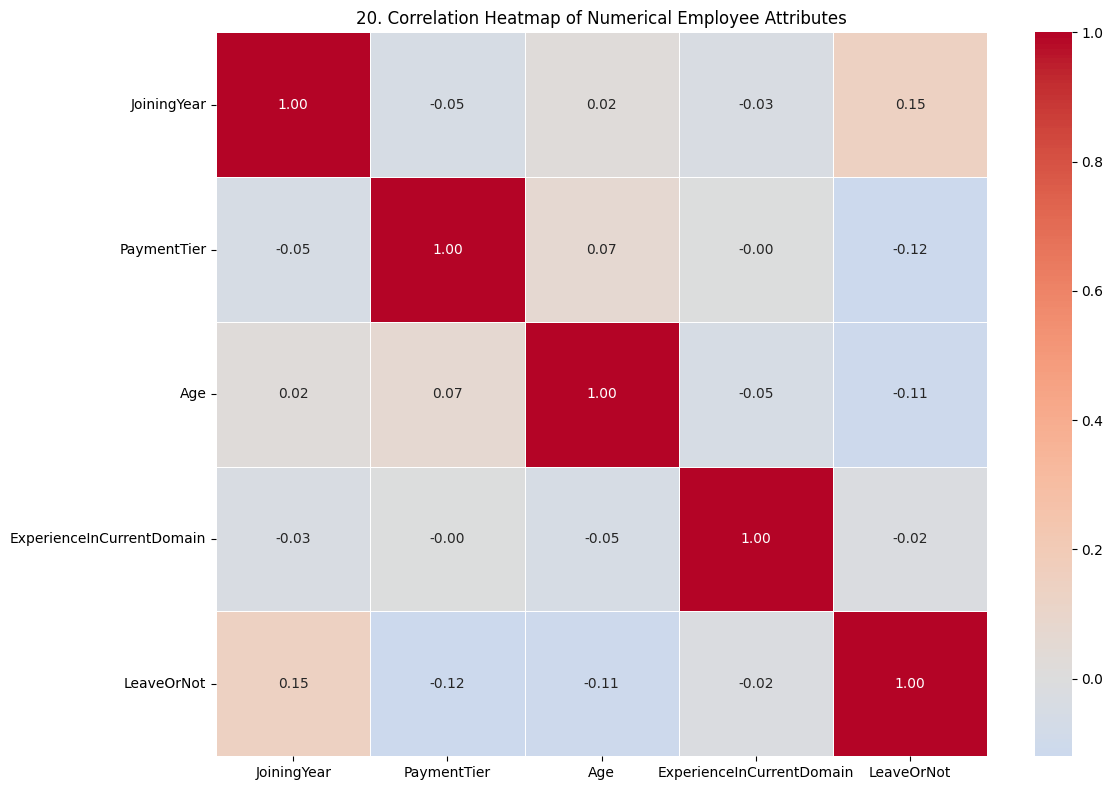

In [33]:
fig = plt.figure(figsize=(12,8))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, center=0)
plt.title(f'{plot_no}. Correlation Heatmap of Numerical Employee Attributes')
show_fig()
plot_no += 1

# Model Training

## Separate features and target

In [34]:
X = df.drop(columns=['LeaveOrNot'])
y = df['LeaveOrNot']

## Identify numerical and categorical columns

In [35]:
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

## Split the dataset

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Preprocess numerical and categorical features

In [37]:
preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
    ]), cat_cols)
])

## Create the gradient boosting pipeline

In [38]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', HistGradientBoostingClassifier(random_state=42))
])

## Tune hyperparameters using cross-validation

In [39]:
params = {
    'model__learning_rate': [0.03, 0.06, 0.1],
    'model__max_iter': [100, 200],
    'model__max_leaf_nodes': [15, 31],
    'model__l2_regularization': [0, 1]
}

search = GridSearchCV(
    pipe, params, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='accuracy', n_jobs=-1
)

## Train and select the best model

In [40]:
search.fit(X_train, y_train)
model = search.best_estimator_

## Predict training and testing data

In [41]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

## Print accuracy scores

In [42]:
print("Best Parameters:", search.best_params_)
print(f"Training Accuracy: {accuracy_score(y_train, y_train_pred):.4f}")
print(f"Testing Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Cross-Validation Accuracy: {search.best_score_:.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_test_pred, zero_division=0))

Best Parameters: {'model__l2_regularization': 1, 'model__learning_rate': 0.03, 'model__max_iter': 200, 'model__max_leaf_nodes': 15}
Training Accuracy: 0.8241
Testing Accuracy:  0.8210
Cross-Validation Accuracy: 0.8069

Classification Report:

              precision    recall  f1-score   support

           0       0.79      0.96      0.87       335
           1       0.90      0.61      0.73       218

    accuracy                           0.82       553
   macro avg       0.85      0.78      0.80       553
weighted avg       0.83      0.82      0.81       553



## Plot the confusion matrix

<Figure size 800x600 with 0 Axes>

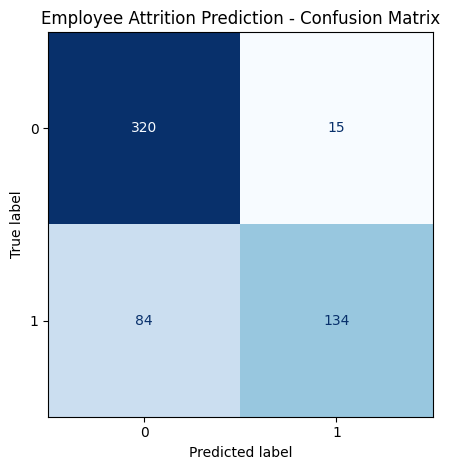

In [43]:
fig = plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, cmap='Blues', colorbar=False
)
plt.title('Employee Attrition Prediction - Confusion Matrix')
plt.tight_layout()
plt.show()